# 09. Transformer 블록과 GPT

GPT = **토큰 임베딩 + 위치 임베딩** → **Transformer 블록 × N** → LayerNorm → 어휘 크기의 출력층

```
idx (B,T) → tok_emb + pos_emb (B,T,C) → Dropout
  → [Block] × n_layers
       x = x + Dropout(MultiHeadAttention(LayerNorm(x), causal))   # 토큰끼리 정보 교환
       x = x + Dropout(FeedForward(LayerNorm(x)))                  # 토큰마다 개별 가공
  → LayerNorm → Linear(C, vocab) → logits (B,T,vocab)
```

06과 같은 Zen of Python 글자 단위 언어 모델을 GPT로 다시 만들어서 비교한다.

> ⏱ CPU 기준 학습 셀(5번)이 약 3~4분 걸립니다. 빨리 보려면 `range(20)`을 `range(10)`으로 줄이세요.

In [1]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)

## 1. 08에서 만든 Multi-Head Attention (그대로 가져옴)

In [2]:
def attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / d_k ** 0.5        # (..., Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(mask, float("-inf"))  # mask가 True인 곳을 가림
    weights = torch.softmax(scores, dim=-1)               # 각 Query 행의 합 = 1
    return weights @ V, weights                           # (..., Tq, d_v)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_head = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x, causal=False):
        B, T, C = x.shape
        def split(t):                                            # (B, T, C) → (B, h, T, d_head)
            return t.view(B, T, self.h, self.d_head).transpose(1, 2)
        q, k, v = split(self.W_q(x)), split(self.W_k(x)), split(self.W_v(x))
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1) if causal else None
        out, w = attention(q, k, v, mask)                        # (B, h, T, d_head)
        out = out.transpose(1, 2).contiguous().view(B, T, C)     # head 이어 붙이기 → (B, T, C)
        return self.out_proj(out), w

## 2. 구성 요소: LayerNorm, FeedForward, 잔차 연결

- **LayerNorm**: 토큰마다 **마지막 차원(특징)** 기준으로 평균 0, 분산 1로 맞춘 뒤 학습 파라미터 `scale`, `shift`를 적용한다. 깊은 네트워크의 학습을 안정시킨다.
  (BatchNorm은 배치 방향으로 정규화한다. 시퀀스 길이와 배치 크기가 바뀌는 언어 모델에는 LayerNorm을 쓴다.)
- **FeedForward**: `C → 4C → GELU → C`. Attention이 모은 정보를 토큰마다 가공한다.
- **잔차 연결** `x + f(x)`: 기울기가 블록을 건너뛰어 바로 흐르는 길이 생겨서, 층이 깊어도 학습이 된다 (06의 기울기 소실 해결).

In [3]:
class LayerNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.scale = nn.Parameter(torch.ones(dim))
        self.shift = nn.Parameter(torch.zeros(dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        return self.scale * (x - mean) / torch.sqrt(var + self.eps) + self.shift


x = torch.randn(2, 3, 8)
print("nn.LayerNorm과 일치:", torch.allclose(LayerNorm(8)(x), nn.LayerNorm(8)(x), atol=1e-6))


class FeedForward(nn.Module):
    def __init__(self, dim, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, dim, n_heads, dropout):
        super().__init__()
        self.ln1 = LayerNorm(dim)
        self.attn = MultiHeadAttention(dim, n_heads)
        self.ln2 = LayerNorm(dim)
        self.ff = FeedForward(dim, dropout)
        self.drop = nn.Dropout(dropout)
        self.last_attn = None                       # 시각화용으로 attention 가중치 저장

    def forward(self, x):
        a, self.last_attn = self.attn(self.ln1(x), causal=True)
        x = x + self.drop(a)                        # 잔차 연결 1
        x = x + self.ff(self.ln2(x))                # 잔차 연결 2
        return x

nn.LayerNorm과 일치: True


## 3. GPT 모델

위치 임베딩 `pos_emb(arange(T))`이 더해지면서 08에서 확인한 "순서를 모르는" 문제가 해결된다.

In [4]:
class GPT(nn.Module):
    def __init__(self, vocab_size, context_len, dim, n_heads, n_layers, dropout=0.1):
        super().__init__()
        self.context_len = context_len
        self.tok_emb = nn.Embedding(vocab_size, dim)
        self.pos_emb = nn.Embedding(context_len, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block(dim, n_heads, dropout) for _ in range(n_layers)])
        self.ln_f = LayerNorm(dim)
        self.head = nn.Linear(dim, vocab_size, bias=False)

    def forward(self, idx):                                     # (B, T)
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))   # (B, T, C)
        x = self.drop(x)
        x = self.blocks(x)
        return self.head(self.ln_f(x))                          # (B, T, vocab)

## 4. 데이터 (06과 동일)

In [5]:
import contextlib, io, codecs
with contextlib.redirect_stdout(io.StringIO()):   # import this 는 화면에 출력하므로 숨김
    import this
text = codecs.decode(this.s, "rot13")             # 파이썬에 내장된 'The Zen of Python' 원문
print(len(text), "글자")
print(text[:180])

856 글자
The Zen of Python, by Tim Peters

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better


In [6]:
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
V = len(chars)
data = torch.tensor([stoi[c] for c in text])

CONTEXT = 64
chunks = data.unfold(0, CONTEXT + 1, 1)
X, Y = chunks[:, :-1], chunks[:, 1:]
loader = DataLoader(TensorDataset(X, Y), batch_size=64, shuffle=True)
print("어휘:", V, "| 샘플:", X.shape)

어휘: 45 | 샘플: torch.Size([792, 64])


## 5. 학습

학습 코드는 06의 RNN과 같다. 모델만 바뀌었다.
RNN과 달리 64개 위치를 **한 번에 병렬로** 계산한다 (Causal Mask 덕분에 각 위치는 자기 앞만 본다).

In [7]:
torch.manual_seed(0)
model = GPT(V, CONTEXT, dim=96, n_heads=4, n_layers=3, dropout=0.1)
print(f"파라미터 수: {sum(p.numel() for p in model.parameters()):,}")
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)

start = time.time()
for epoch in range(20):
    model.train()
    total = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model(xb)                                              # (B, T, V)
        loss = F.cross_entropy(logits.flatten(0, 1), yb.flatten())      # (B*T, V) vs (B*T,)
        loss.backward()
        optimizer.step()
        total += loss.item()
    if epoch % 5 == 0 or epoch == 19:
        print(f"epoch {epoch:2d}  loss {total / len(loader):.3f}")
print(f"({time.time() - start:.0f}s)")

파라미터 수: 349,632


epoch  0  loss 2.819


epoch  5  loss 1.373


epoch 10  loss 0.410


epoch 15  loss 0.190


epoch 19  loss 0.142
(209s)


## 6. 생성: temperature 와 top-k

1. 마지막 `context_len`개 토큰만 남긴다 (위치 임베딩 크기 제한).
2. **마지막 위치**의 logits만 사용한다.
3. `temperature`로 나누고, `top_k`면 상위 k개 밖은 `-inf`로 지운다.
4. softmax → 샘플링 → 이어 붙이기를 반복한다.

RNN과 달리 상태를 넘기지 않으므로 매번 문맥 전체를 다시 계산한다. 실제 서비스에서는 KV cache로 이 비용을 줄인다.

In [8]:
@torch.no_grad()
def generate(model, prompt, n=200, temperature=1.0, top_k=None):
    model.eval()
    idx = torch.tensor([[stoi[c] for c in prompt]])
    for _ in range(n):
        idx_cond = idx[:, -model.context_len:]
        logits = model(idx_cond)[:, -1, :] / temperature       # (1, V)
        if top_k is not None:
            kth = torch.topk(logits, top_k).values[:, [-1]]
            logits[logits < kth] = float("-inf")
        probs = torch.softmax(logits, dim=-1)
        nxt = torch.multinomial(probs, 1)                      # greedy라면 argmax
        idx = torch.cat([idx, nxt], dim=1)
    return "".join(itos[i] for i in idx[0].tolist())

torch.manual_seed(0)
print(generate(model, "Beautiful is", temperature=0.5))
print("-" * 60)
print(generate(model, "Beautiful is", temperature=1.0, top_k=5))

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Spe
------------------------------------------------------------


Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Spe


## 7. 학습된 Attention 들여다보기

첫 번째 블록의 head별 가중치. Causal Mask 때문에 아래 삼각형만 값이 있고, head마다 보는 위치가 다르다.

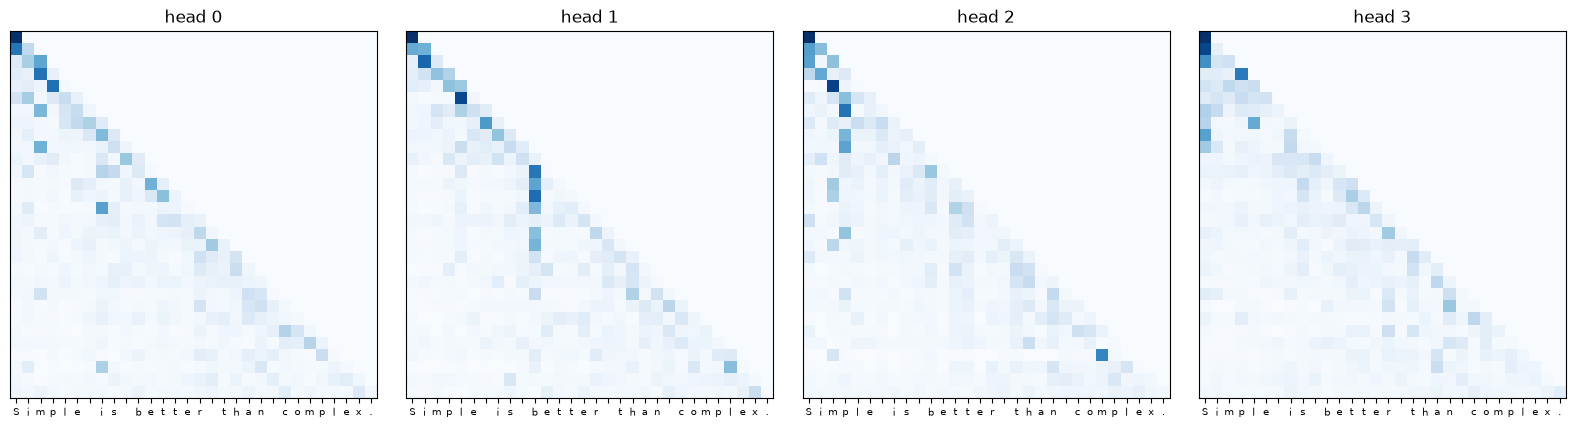

In [9]:
prompt = "Simple is better than complex."
model.eval()
with torch.no_grad():
    model(torch.tensor([[stoi[c] for c in prompt]]))
w = model.blocks[0].last_attn[0]                     # (heads, T, T)

fig, axes = plt.subplots(1, w.shape[0], figsize=(16, 4))
for h, ax in enumerate(axes):
    ax.imshow(w[h], cmap="Blues")
    ax.set_title(f"head {h}")
    ax.set_xticks(range(len(prompt)))
    ax.set_xticklabels(list(prompt), fontsize=7)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## 8. 실제 GPT-2와의 차이는 크기뿐

| | 이 노트북 | GPT-2 small |
| --- | --- | --- |
| 토큰화 | 글자 | BPE (tiktoken `gpt2`) |
| vocab_size | 약 30 | 50,257 |
| context_len | 64 | 1,024 |
| dim / heads / layers | 96 / 4 / 3 | 768 / 12 / 12 |

같은 `GPT` 클래스로 GPT-2 크기를 만들어 파라미터 수를 세어 본다 (메모리 약 650MB 사용).
출력층을 토큰 임베딩과 **공유(weight tying)** 하면 우리가 아는 "124M"이 된다.

In [10]:
gpt2 = GPT(vocab_size=50257, context_len=1024, dim=768, n_heads=12, n_layers=12)
n = sum(p.numel() for p in gpt2.parameters())
print(f"전체        : {n:,}")
gpt2.head.weight = gpt2.tok_emb.weight                 # weight tying
n_tied = sum(p.numel() for p in gpt2.parameters())     # 공유된 파라미터는 한 번만 셈
print(f"weight tying: {n_tied:,}")
del gpt2

전체        : 163,009,536
weight tying: 124,412,160


## 다음 단계 (교안 Chapter 5~7)

- **사전학습**: 이 학습 루프를 거대한 텍스트로 오래 돌린 것
- **파인튜닝(분류)**: 마지막 `head`를 `Linear(dim, 클래스 수)`로 바꾸고, 마지막 토큰의 출력으로 분류
- **LoRA**: 원래 가중치 $W$는 고정하고, 작은 행렬 두 개의 곱 $AB$만 학습해서 $W + AB$로 사용
- **Instruction tuning**: (지시, 응답) 형식의 텍스트로 이어서 학습